<a href="https://colab.research.google.com/github/sotetsuk/LectureColab/blob/main/torch_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split

# データ作成
X, y = make_circles(n_samples=200, noise=0.15, factor=0.4, random_state=42)

print(X.shape)  # X: (200, 2)
print(y.shape)  # y: (200,)

# Train/Test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# NumPy配列をPyTorchテンソルに変換
X_train = torch.FloatTensor(X_train)
y_train = torch.FloatTensor(y_train).unsqueeze(1)

X_test = torch.FloatTensor(X_test)
y_test = torch.FloatTensor(y_test).unsqueeze(1)

# DataLoaderの作成
train_dataset = TensorDataset(X_train, y_train)
train_dataloader = DataLoader(train_dataset, batch_size=16, shuffle=True)

test_dataset = TensorDataset(X_test, y_test)
test_dataloader = DataLoader(test_dataset, batch_size=16, shuffle=False)

model = nn.Sequential(
    nn.Linear(2, 4),
    nn.ReLU(),
    nn.Linear(4, 2),
    nn.ReLU(),
    nn.Linear(2, 1),
    nn.Sigmoid()
)

optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.BCELoss()

for epoch in range(200):
    model.train()

    epoch_loss = 0.0
    train_correct = 0
    train_total = 0

    for batch_X, batch_y in train_dataloader:
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()

        epoch_loss += loss.item()

        # Train Accuracy
        predicted = (outputs > 0.5).float()
        train_total += batch_y.size(0)
        train_correct += (predicted == batch_y).sum().item()

    train_accuracy = 100 * train_correct / train_total

    print(
        f'Epoch [{epoch+1}/200], '
        f'Train Loss: {epoch_loss:.4f}, '
        f'Train Accuracy: {train_accuracy:.2f}%'
    )

# Test Accuracy を計算
model.eval()

test_loss = 0.0
test_correct = 0
test_total = 0

with torch.no_grad():
    for batch_X, batch_y in test_dataloader:
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)

        test_loss += loss.item()

        predicted = (outputs > 0.5).float()
        test_total += batch_y.size(0)
        test_correct += (predicted == batch_y).sum().item()

test_accuracy = 100 * test_correct / test_total

print(
    f'Final Test Loss: {test_loss:.4f}, '
    f'Final Test Accuracy: {test_accuracy:.2f}%'
)

(200, 2)
(200,)
Epoch [1/200], Train Loss: 7.6637, Train Accuracy: 50.00%
Epoch [2/200], Train Loss: 7.2995, Train Accuracy: 50.00%
Epoch [3/200], Train Loss: 7.0496, Train Accuracy: 50.00%
Epoch [4/200], Train Loss: 6.8904, Train Accuracy: 50.00%
Epoch [5/200], Train Loss: 6.7522, Train Accuracy: 50.00%
Epoch [6/200], Train Loss: 6.5706, Train Accuracy: 50.00%
Epoch [7/200], Train Loss: 6.4229, Train Accuracy: 50.00%
Epoch [8/200], Train Loss: 6.2387, Train Accuracy: 50.00%
Epoch [9/200], Train Loss: 6.0501, Train Accuracy: 50.00%
Epoch [10/200], Train Loss: 5.8840, Train Accuracy: 50.00%
Epoch [11/200], Train Loss: 5.6915, Train Accuracy: 66.25%
Epoch [12/200], Train Loss: 5.4803, Train Accuracy: 70.62%
Epoch [13/200], Train Loss: 5.2582, Train Accuracy: 78.12%
Epoch [14/200], Train Loss: 5.0735, Train Accuracy: 75.00%
Epoch [15/200], Train Loss: 4.8113, Train Accuracy: 83.75%
Epoch [16/200], Train Loss: 4.5907, Train Accuracy: 82.50%
Epoch [17/200], Train Loss: 4.3670, Train Accurac

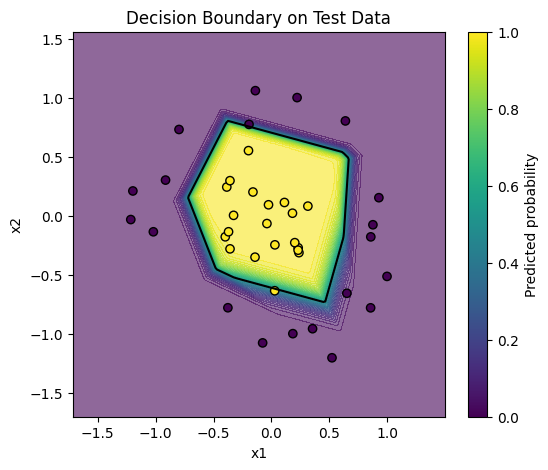

In [2]:
import numpy as np
import matplotlib.pyplot as plt

model.eval()

x_min, x_max = X_test[:, 0].min() - 0.5, X_test[:, 0].max() + 0.5
y_min, y_max = X_test[:, 1].min() - 0.5, X_test[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = torch.FloatTensor(np.c_[xx.ravel(), yy.ravel()])

with torch.no_grad():
    probs = model(grid).reshape(xx.shape)

plt.figure(figsize=(6, 5))

plt.contourf(xx, yy, probs, levels=50, alpha=0.6)
plt.contour(xx, yy, probs, levels=[0.5], colors="black")

plt.scatter(
    X_test[:, 0],
    X_test[:, 1],
    c=y_test.squeeze(),
    edgecolors="black"
)

plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Decision Boundary on Test Data")
plt.colorbar(label="Predicted probability")
plt.show()